# 05 - Evaluate the selected model on held-out engines

Run notebook 04 first (or `uv run pm-train`). This notebook generates predictions from the saved serving artifact, strictly aligns engine/cycle keys, and reports the final recorded cycle of every test engine. Targets use the same RUL cap as training.

MAE and RMSE measure error in cycles. PHM08 penalizes overestimation more strongly than underestimation. Scores here do not change which model is selected.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
import json
from predictive_maintenance.models.predict import predict
from predictive_maintenance.models.evaluate import evaluate, align_predictions, calculate_metrics

manifest_path = MODELS_DIR / "best_model.json"
if not manifest_path.exists():
    raise FileNotFoundError("Run notebook 04 or `uv run pm-train` before evaluation.")
manifest = json.loads(manifest_path.read_text())
predictions_path = PROCESSED_DATA_DIR / "test_predictions.csv"
labels_path = PROCESSED_DATA_DIR / "test_labels.csv"
predict(manifest_path, PROCESSED_DATA_DIR / "test_features.csv", predictions_path)
evaluate(predictions_path, labels_path, RESULTS_DIR / "evaluation.csv",
         RESULTS_DIR / "evaluation_by_unit.csv")
metrics = pd.read_csv(RESULTS_DIR / "evaluation.csv")
display(metrics)

joined = align_predictions(pd.read_csv(predictions_path), pd.read_csv(labels_path))
last = joined.loc[joined.groupby("unit").cycle.idxmax()].sort_values("unit")
assert len(last) == int(metrics.n_engines.iloc[0])
np.testing.assert_allclose(metrics.RMSE.iloc[0], manifest["test_RMSE"])
display(last.head())


,MAE,RMSE,R2,PHM08,n_engines
0,11.826881,16.37704,0.832983,607.393744,100


,unit,cycle,prediction,RUL
30,1,31,119.170867,112
79,2,49,119.492035,98
205,3,126,62.947068,69
311,4,106,98.020206,82
409,5,98,99.704240,91


## Predictions and residuals at the last test cycle


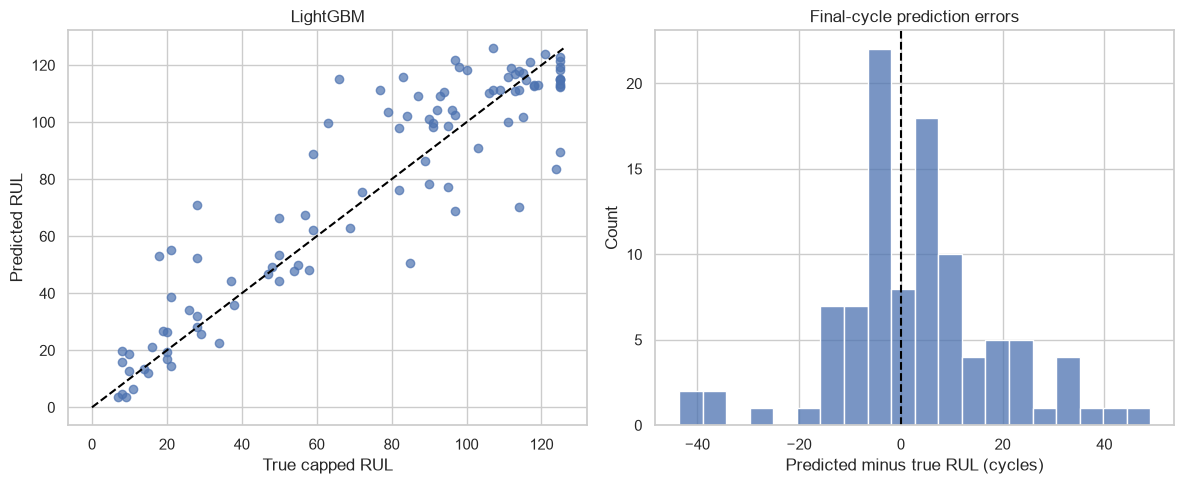

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(last.RUL, last.prediction, alpha=0.7)
limit = max(last.RUL.max(), last.prediction.max())
axes[0].plot([0, limit], [0, limit], "--", color="black")
axes[0].set(xlabel="True capped RUL", ylabel="Predicted RUL", title=manifest["model_name"])
residuals = last.prediction - last.RUL
sns.histplot(residuals, bins=20, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="Final-cycle prediction errors", xlabel="Predicted minus true RUL (cycles)")
plt.tight_layout()
plt.show()


## Actual versus predicted remaining life by engine


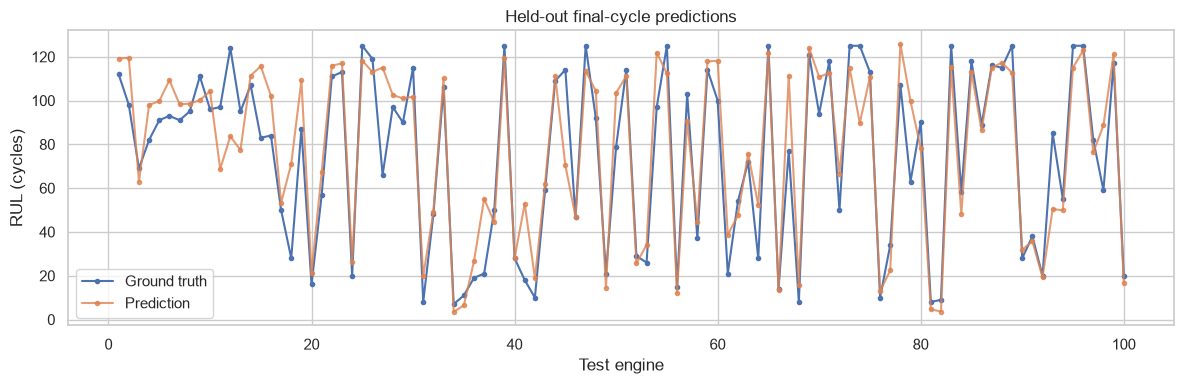

,unit,cycle,prediction,RUL,absolute_error
3201,27,140,115.065782,66,49.065782
5664,45,152,70.375055,114,43.624945
2115,18,133,71.020080,28,43.020080
1387,12,217,83.638218,124,40.361782
10254,79,101,99.680797,63,36.680797
9626,74,137,89.698591,125,35.301409
5130,41,123,52.917211,18,34.917211
12226,93,244,50.494149,85,34.505851
8785,67,71,111.314758,77,34.314758
4712,37,121,55.165563,21,34.165563


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(last.unit, last.RUL, label="Ground truth", marker=".")
ax.plot(last.unit, last.prediction, label="Prediction", marker=".", alpha=0.8)
ax.set(xlabel="Test engine", ylabel="RUL (cycles)", title="Held-out final-cycle predictions")
ax.legend()
plt.tight_layout()
plt.show()
display(last.assign(absolute_error=abs(last.prediction - last.RUL)).nlargest(10, "absolute_error"))


## Verify the API feature path without starting an HTTP server


In [6]:
from predictive_maintenance.api.inference import ModelService

service = ModelService(MODELS_DIR)
service.load()
raw_test = pd.read_csv(RAW_DATA_DIR / "test_data.csv")
unit = int(last.unit.iloc[0])
readings = raw_test.loc[raw_test.unit == unit].sort_values("cycle").drop(columns=["unit", "cycle"]).to_dict("records")
api_result = service.predict(readings, unit=f"engine_{unit:03d}")
expected = float(last.loc[last.unit == unit, "prediction"].iloc[0])
assert abs(api_result["predicted_rul"] - expected) <= 0.0051
display(pd.Series(api_result, name="API prediction").to_frame())


,API prediction
unit,engine_001
predicted_rul,119.17
predicted_class,healthy
model_name,LightGBM
n_readings_received,31
n_readings_used,10
latency_ms,47.82
